# 🧹 실험 C — 데이터 청소: 앱이 보는 장면만 남기면 나아질까?

실험 A(yolo11n 전체 미세조정, 10종, Open Images, imgsz 640, 50에폭 · patience 10)의 val mAP50은 **0.63**이었다.
클래스별로 보면 차이가 크다.

| 마우스 | 칫솔 | 휴지 | 안경 | 모자 | 우산 | 양말 | 신발 | 문 | 책 |
|---|---|---|---|---|---|---|---|---|---|
| .87 | .85 | .82 | .75 | .71 | .70 | .51 | .42 | .36 | .33 |

### 원인이 아닌 것

- **클래스 불균형이 아니다.** 책·신발은 박스가 **가장 많은데** 점수가 가장 낮고, 칫솔은 박스가 가장 적은데 점수가 높다.
- **입력 정규화도 아니다.** 학습 · 검증 · 웹앱 모두 `/255`이고 확인했다.

### 가설: 장면이 다르다

앱은 **물건 하나를, 크게, 가운데에** 비춘다. 그런데 Open Images 학습 박스에는 이런 것이 많다.

| 종류 | 뜻 | 예 |
|---|---|---|
| `IsGroupOf` | 박스 하나가 **여러 개를 한꺼번에** 감쌈 | 책장 전체 = 책 박스 1개 (책의 61%) |
| `IsDepiction` | 진짜 물건이 아니라 **그림 · 사진 속** 물건 | 포스터 속 우산 |
| 작은 박스 | 사진 면적의 **1% 미만** | 신발 74%, 안경 49% |

셋 중 하나라도 해당하면 "지울 박스"로 본다. 클래스별 지울 박스 비율(train): 책 76%, 신발 75%, 안경 50%, 칫솔 37%, 휴지 36%, 우산 29%, 모자 29%, 양말 25%, **문 15%**, 마우스 14%.

**예측**: 지울 박스가 많은 책 · 신발 · 안경은 좋아지고, 문(15%만 지움)은 별로 안 바뀐다.
→ 문이 안 바뀐다면, 문의 낮은 점수는 *장면* 말고 다른 이유(문 자체가 애매함 등)라는 뜻이다.

### 그냥 라벨만 지우면 안 되는 이유 — 빠진 라벨 함정

박스만 지우고 사진은 그대로 두면, 사진 속 책장은 그대로 있는데 라벨이 없다 → 모델은 "책장 = **배경**"이라고 배운다.
그래서 **지운 박스 자리를 회색(114, 114, 114)으로 칠한다.** 이 색은 YOLO가 사진 크기를 맞출 때 빈 곳을 채우는 색(레터박스)이라
모델에게 "여기는 아무것도 없음"으로 익숙한 색이다. 단, **남긴 박스 안의 픽셀은 칠하지 않는다.**

```
칠할 곳 = (지울 박스들의 합집합) − (남길 박스들의 합집합)
```

| 단계 | 내용 |
|---|---|
| 0 | 설정 |
| 1 | 왜 청소하나 — 클래스별 묶음 · 그림 · 작음 비율 |
| 2 | 청소 규칙 + 내보내기 (train, val 모두) |
| 3 | 전/후 비교 그림 |
| 4 | 실험 C 학습 + 학습곡선 (A vs C) |
| 5 | 2×2 평가 (모델 A·C × val 원본·청소본) |
| 6 | 앱 기준 통과율 (가장 앱에 가까운 지표) |
| 7 | 결론 + 다음 단계 |

## 0. 설정

실험 A의 가중치는 `wakeup_mission.ipynb`에서 학습한 것을 그대로 쓴다. 원본 데이터(`data/yolo`)도 그 노트북이 만든 것이다.

In [1]:
import sys, time, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cv2, torch
from ultralytics import YOLO
from IPython.display import display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config as C, data as D, evaluate as E, clean as K

QUICK = False                      # True: 클래스당 20장(val 10장) · 2에폭 (끝까지 도는지만 확인)
PER_CLASS = {'train': 20 if QUICK else 400, 'validation': 10 if QUICK else 80}
EPOCHS = 2 if QUICK else 50
DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
DATA = ROOT / 'data'
SUFFIX = '_quick' if QUICK else ''
YOLO_DIR = DATA / f'yolo{SUFFIX}'                 # 원본 (wakeup_mission.ipynb가 만든 것, 여기서는 읽기만)
CLEAN_DIR = DATA / f'yolo_clean{SUFFIX}'          # 청소본 (이 노트북이 만듦)
CROPS_DIR = DATA / f'mission_crops{SUFFIX}'       # 앱처럼 잘라 낸 val 사진
RUNS = ROOT / ('runs_quick' if QUICK else 'runs')
MIN_AREA = 0.01                                   # 사진 면적의 1% 미만 박스는 지움

A_WEIGHTS = RUNS / 'A_full' / 'weights' / 'best.pt'
assert A_WEIGHTS.exists(), f'{A_WEIGHTS} 가 없어요. 먼저 wakeup_mission.ipynb에서 실험 A를 학습하세요.'
assert (YOLO_DIR / 'dataset.yaml').exists(), f'{YOLO_DIR} 가 없어요. 먼저 wakeup_mission.ipynb를 실행하세요.'

plt.rcParams['font.family'] = 'AppleGothic'; plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.precision', 3)
print('device:', DEVICE, '| QUICK:', QUICK, '| A 가중치:', A_WEIGHTS.relative_to(ROOT))

/Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps | QUICK: False | A 가중치: runs/A_full/weights/best.pt


## 1. 왜 청소하나 — 클래스별로 얼마나 지워지나

FiftyOne에 저장된 Open Images 원래 박스(겹친 박스 제거 전)를 센다. 한 박스가 여러 이유에 걸릴 수 있어서 `지움%`는 세 비율의 합보다 작을 수 있다.

- `묶음%`: IsGroupOf · `그림%`: IsDepiction · `작음%`: 면적 1% 미만 · `지움%`: 셋 중 하나라도

In [2]:
views = {}
for split, yolo_split in [('train', 'train'), ('validation', 'val')]:
    views[yolo_split] = D.to_mission_view(D.load_split(split, PER_CLASS[split]))

reasons = {}
for s, v in views.items():
    reasons[s] = K.reason_table(v, MIN_AREA).set_index('id')

why = reasons['train'][['클래스']].copy()
for s in ['train', 'val']:
    for col in ['박스', '묶음%', '그림%', '작음%', '지움%']:
        why[f'{s} {col}'] = reasons[s][col]
why.sort_values('train 지움%', ascending=False)

,클래스,train 박스,train 묶음%,train 그림%,train 작음%,train 지움%,val 박스,val 묶음%,val 그림%,val 작음%,val 지움%
id,,,,,,,,,,,
2,책,2187,60.5,1.2,37.6,75.5,672,66.8,0.1,35.4,79.6
8,신발,2628,1.8,1.3,74.4,74.9,404,0.0,0.0,75.2,75.2
9,안경,1441,0.0,1.9,48.7,50.1,229,0.4,5.7,41.5,44.1
6,휴지,377,6.4,1.9,26.8,34.0,5,20.0,0.0,40.0,40.0
4,모자,1000,0.6,3.4,25.2,29.0,215,0.5,2.3,18.1,20.5
1,우산,1033,5.4,3.6,20.6,28.8,40,15.0,5.0,7.5,27.5
7,양말,1128,1.7,1.5,13.6,16.0,25,8.0,0.0,0.0,8.0
5,문,633,0.0,2.8,13.0,15.3,111,1.8,2.7,8.1,12.6
3,칫솔,219,3.2,0.0,11.4,14.6,16,6.2,0.0,0.0,6.2


`train 지움%`가 높은 클래스와 실험 A에서 mAP50이 낮은 클래스(책 · 신발)가 겹치는지 보자. 문은 지울 박스가 적은데도 점수가 낮다 — 문은 청소로 안 풀릴 것으로 예측한다.

## 2. 청소 규칙 + 내보내기

박스마다:

1. `IsGroupOf` 이거나 `IsDepiction` 이거나 면적이 1% 미만이면 **지움**, 아니면 **남김** (`K.should_drop`)
   - 단, 다섯 속성이 모두 True인 박스는 원본 CSV의 -1(모름)을 FiftyOne이 True로 읽은 것 → **면적 규칙만** 적용 (EDA 노트북 참고)
2. 지운 박스 자리를 회색으로 칠함 — 남긴 박스 안은 그대로 (`K.paint_mask`)
3. 남긴 박스만 YOLO 라벨로 쓰고, 같은 클래스끼리 IoU 0.7 이상 겹치면 하나만 남김 (원본과 같은 규칙)

박스가 **모두 지워진 사진**도 버리지 않고 빈 라벨로 둔다 → "회색 = 아무것도 없음"을 배우는 배경 사진이 된다.
**val도 같은 규칙으로 청소한다.** (원본 val은 5장에서 그대로 비교에 쓴다)

In [3]:
clean_stats = {}
for s, v in views.items():
    t0 = time.time()
    clean_stats[s] = K.clean_and_export(v, CLEAN_DIR, s, MIN_AREA)   # 끝난 표시(labels/<split>.done)가 있으면 저장된 통계만 읽음
    st = clean_stats[s]
    print(f"{s}: 사진 {st['images']}장 · 모든 박스가 지워진 사진 {st['all_dropped']}장 · {time.time() - t0:.0f}초")
CLEAN_YAML = CLEAN_DIR / 'dataset.yaml'
print(CLEAN_YAML.read_text())

train: 사진 3237장 · 모든 박스가 지워진 사진 579장 · 0초
val: 사진 432장 · 모든 박스가 지워진 사진 108장 · 0초
path: /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/yolo_clean
train: images/train
val: images/val
names:
  0: mouse
  1: umbrella
  2: book
  3: toothbrush
  4: hat
  5: door
  6: toilet_paper
  7: sock
  8: shoe
  9: glasses



In [4]:
# 클래스별 남김 / 지움 (남김은 겹친 박스 제거 후 개수라서 1절의 지움%와 조금 다를 수 있다)
stats = {s: K.stats_table(clean_stats[s]).set_index('id') for s in clean_stats}
kept_table = stats['train'][['클래스']].copy()
for s in ['train', 'val']:
    for col in ['남김', '지움', '지움%']:
        kept_table[f'{s} {col}'] = stats[s][col]
kept_table

,클래스,train 남김,train 지움,train 지움%,val 남김,val 지움,val 지움%
id,,,,,,,
0,마우스,389,65,14.3,22,2,8.3
1,우산,608,298,32.9,25,11,30.6
2,책,527,1651,75.8,123,535,81.3
3,칫솔,174,32,15.5,15,1,6.2
4,모자,537,290,35.1,103,44,29.9
5,문,501,97,16.2,91,14,13.3
6,휴지,244,128,34.4,3,2,40.0
7,양말,713,181,20.2,16,2,11.1
8,신발,359,1969,84.6,71,304,81.1


## 3. 전/후 비교

빨강 = 지운 박스, 초록 = 남긴 박스. 지울 박스가 많은 **책 · 신발** 사진을 먼저 고른다.

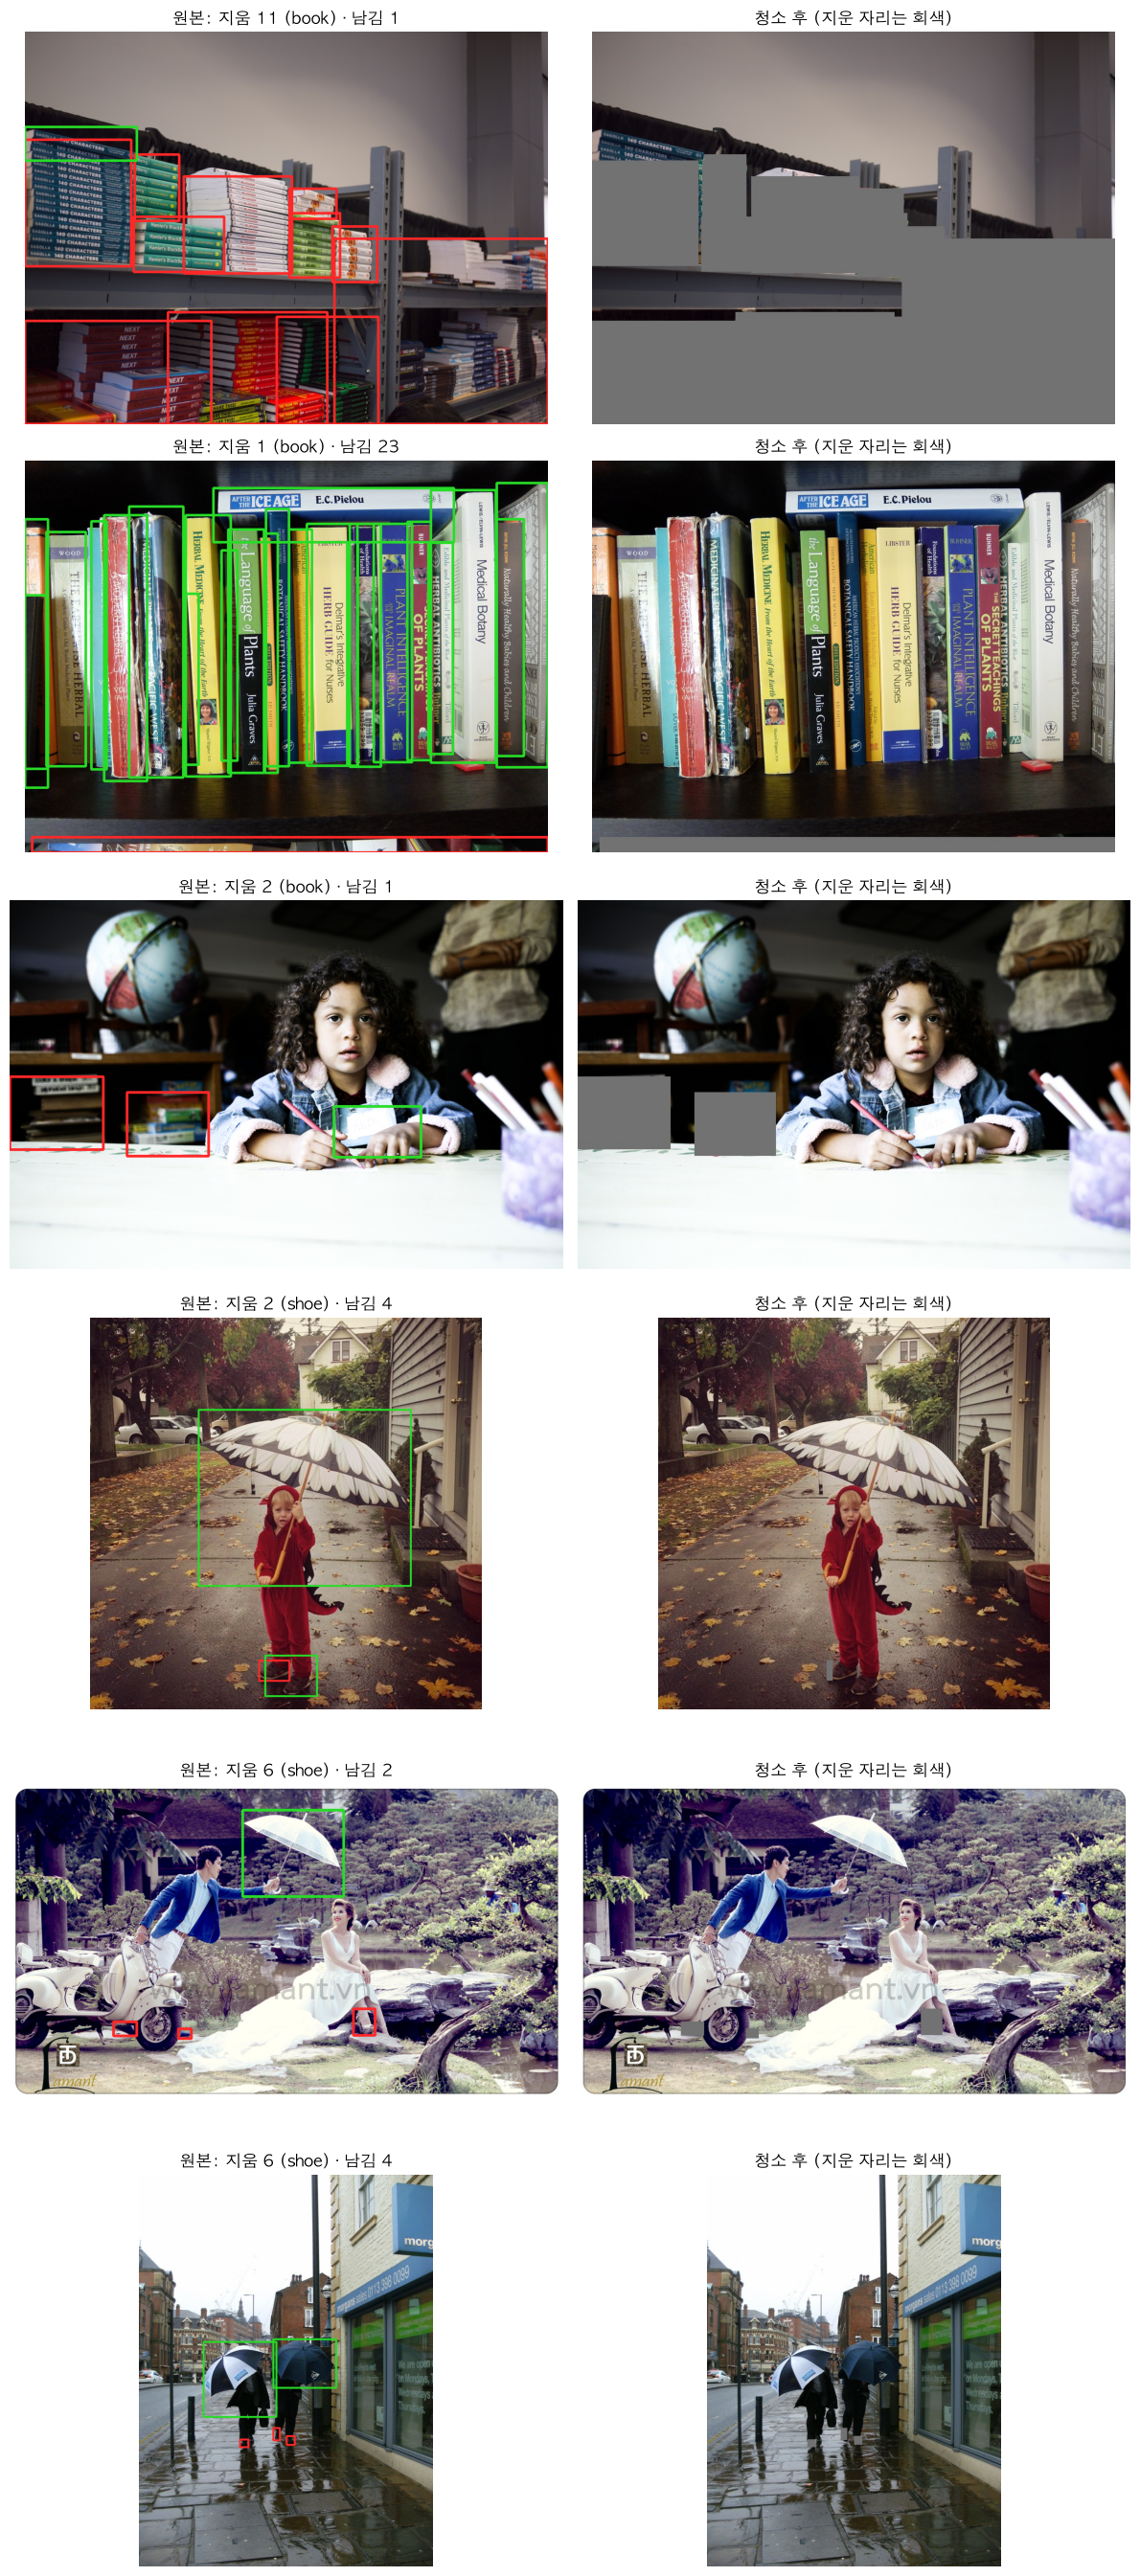

In [5]:
def pick_examples(view, keys=('book', 'shoe'), per_key=3):
    """keys 클래스의 박스가 지워진 사진을 per_key장씩 고른다. 모자라면 아무 박스나 지워진 사진으로 채운다."""
    picked = {k: [] for k in keys}
    others = []
    for s in view:
        kept, dropped = K.split_dets(s.ground_truth.detections, MIN_AREA)
        if not dropped:
            continue
        dropped_keys = {d.label for d in dropped}
        for k in keys:
            if k in dropped_keys and len(picked[k]) < per_key:
                picked[k].append(s)
                break
        else:
            if len(others) < per_key * len(keys):
                others.append(s)
        if all(len(p) == per_key for p in picked.values()):
            break
    chosen = [s for k in keys for s in picked[k]]
    return (chosen + others)[:per_key * len(keys)]


def draw_boxes(img, dets, color):
    h, w = img.shape[:2]
    for d in dets:
        x1, y1, x2, y2 = K.box_px(d.bounding_box, h, w)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, max(2, w // 250))


examples = pick_examples(views['train'])
fig, axes = plt.subplots(len(examples), 2, figsize=(12, 4.5 * len(examples)))
for row, s in zip(axes, examples):
    kept, dropped = K.split_dets(s.ground_truth.detections, MIN_AREA)
    before = cv2.imread(s.filepath)[:, :, ::-1].copy()
    draw_boxes(before, dropped, (255, 40, 40))     # 빨강 = 지움
    draw_boxes(before, kept, (40, 220, 40))        # 초록 = 남김
    after = cv2.imread(str(CLEAN_DIR / 'images' / 'train' / (Path(s.filepath).stem + '.jpg')))[:, :, ::-1]
    row[0].imshow(before); row[0].set_title(f'원본: 지움 {len(dropped)} ({", ".join(sorted({d.label for d in dropped}))}) · 남김 {len(kept)}')
    row[1].imshow(after);  row[1].set_title('청소 후 (지운 자리는 회색)')
    row[0].axis('off'); row[1].axis('off')
plt.tight_layout(); plt.show()

확인할 것:

- 책장 · 신발 무더기가 회색으로 덮였나?
- 남긴 박스(초록) 안은 원래 사진 그대로인가? 지운 박스가 남긴 박스와 겹치면 겹친 부분은 칠하지 않는다.
  그래서 남긴 박스 **안에 있는** 작은 물건(예: 우산 박스 안의 작은 안경)은 라벨 없이 그대로 남는다 — 청소로 다 없앨 수 없는 빠진 라벨이다.

## 4. 실험 C 학습 — 청소한 데이터로 전체 미세조정

설정은 실험 A와 **똑같다** (yolo11n.pt에서 시작, imgsz 640, batch 16, patience 10, seed 0). 바뀐 것은 데이터뿐이다.

In [6]:
C_DIR = RUNS / 'C_clean'
done = C_DIR / 'done'                 # 학습이 끝까지 돌았다는 표시 (중단된 학습의 best.pt는 재사용하지 않음)
if done.exists():
    print('C_clean 이미 학습됨 → 건너뜀')
else:
    t0 = time.time()
    YOLO('yolo11n.pt').train(data=str(CLEAN_YAML), epochs=EPOCHS, imgsz=640, batch=16, patience=10,
                             device=DEVICE, project=str(RUNS), name='C_clean', exist_ok=True,
                             seed=0, workers=4, plots=True)
    done.touch()
    print(f'학습 시간: {(time.time() - t0) / 60:.1f}분')
C_WEIGHTS = C_DIR / 'weights' / 'best.pt'

C_clean 이미 학습됨 → 건너뜀


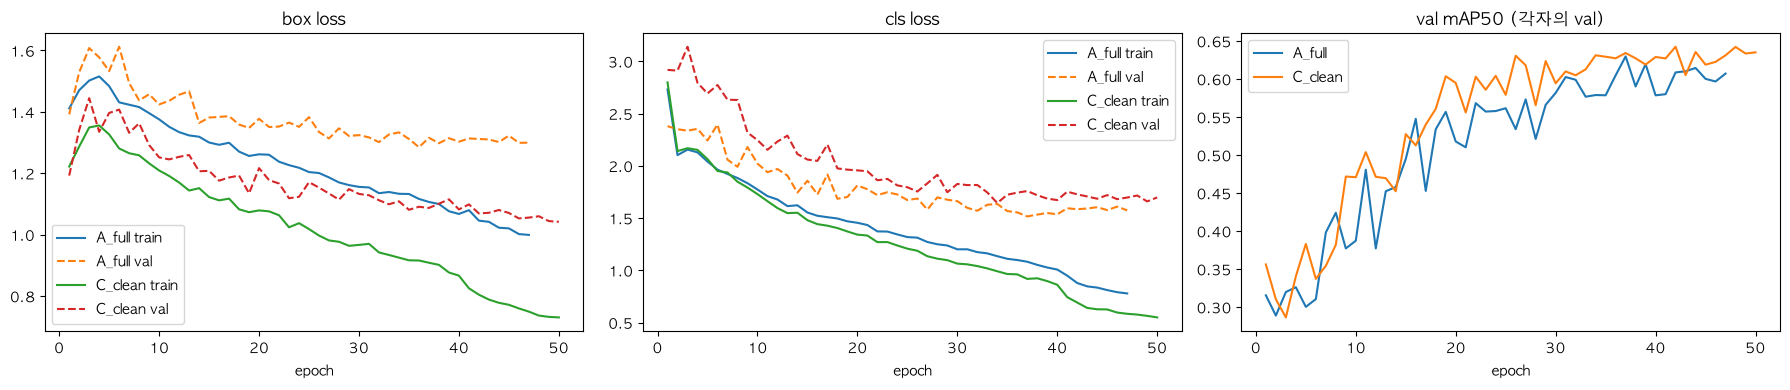

In [7]:
# 학습곡선 A vs C — 주의: val mAP50은 각자 자기 val(A=원본, C=청소본)로 잰 값이라 직접 비교하면 안 된다 (5절에서 같은 val로 비교)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for name in ['A_full', 'C_clean']:
    r = pd.read_csv(RUNS / name / 'results.csv'); r.columns = r.columns.str.strip()
    axes[0].plot(r['epoch'], r['train/box_loss'], label=f'{name} train'); axes[0].plot(r['epoch'], r['val/box_loss'], '--', label=f'{name} val')
    axes[1].plot(r['epoch'], r['train/cls_loss'], label=f'{name} train'); axes[1].plot(r['epoch'], r['val/cls_loss'], '--', label=f'{name} val')
    axes[2].plot(r['epoch'], r['metrics/mAP50(B)'], label=name)
for ax, t in zip(axes, ['box loss', 'cls loss', 'val mAP50 (각자의 val)']):
    ax.set_title(t); ax.legend(); ax.set_xlabel('epoch')
plt.tight_layout(); plt.show()

## 5. 2×2 평가 — 모델(A, C) × 검증 세트(원본, 청소본)

| | val 원본 | val 청소본 |
|---|---|---|
| **모델 A** (원본으로 학습) | A·원본 (= 실험 A 결과) | A·청소 |
| **모델 C** (청소본으로 학습) | C·원본 | C·청소 |

읽는 법:

- **A·원본 → A·청소**: 모델은 그대로, 시험 문제만 바꿨다. 여기서 오르는 만큼은 A가 못 해서가 아니라
  **평가 문제**(앱이 절대 보지 않는 책장 · 작은 신발까지 맞히라고 한 것)였다는 뜻이다.
- **A·청소 → C·청소**: 시험은 같고 모델만 바꿨다. 이 차이가 **청소한 데이터로 학습한 효과**다.
- **C·원본**: 청소본으로 배운 모델이 묶음 · 작은 박스를 얼마나 놓치게 됐는지 (앱에는 상관없지만 참고용).

In [8]:
models = {'A': YOLO(A_WEIGHTS), 'C': YOLO(C_WEIGHTS)}
val_sets = {'원본': YOLO_DIR / 'dataset.yaml', '청소': CLEAN_YAML}
run_name = {'원본': 'orig', '청소': 'clean'}          # 폴더 이름은 영문으로

ROWS = list(range(len(C.CLASSES))) + ['전체']
grid = pd.DataFrame({'클래스': [c.ko for c in C.CLASSES] + ['전체']}, index=ROWS)
for vn, yaml in val_sets.items():          # 열 순서: A·원본, C·원본, A·청소, C·청소
    for mn, model in models.items():
        m = model.val(data=str(yaml), imgsz=640, batch=16, device=DEVICE, project=str(RUNS),
                      name=f'{mn}_val_{run_name[vn]}', exist_ok=True, plots=False, verbose=False)
        per_class = E.per_class_table(m, C.KEYS).set_index('id')['mAP50']
        col = per_class.reindex(range(len(C.CLASSES))).tolist()   # 박스가 없는 클래스가 빠져도 줄이 안 어긋나게 id로 맞춤
        grid[f'{mn}·{vn}'] = col + [m.box.map50]
grid['평가효과(A청소-A원본)'] = grid['A·청소'] - grid['A·원본']
grid['학습효과(C청소-A청소)'] = grid['C·청소'] - grid['A·청소']
grid.round(3)

Ultralytics 8.4.208 🚀 Python-3.12.15 torch-2.15.0 MPS (Apple M4 Pro)


YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3956.5±3231.5 MB/s, size: 473.2 KB)


val: Scanning /Users/kks/Downloads/2026.07-12_여름방학·2학기/ROKEY_부트캠프/딥러닝/wakeup_mission/data/yolo/labels/val.cache... 432 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 432/432 86.3Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 4.1it/s 6.5s

                   all        432       1393       0.73       0.59      0.634      0.468


... (19 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 6.7it/s 4.0s

                   all        432        536      0.687      0.608      0.634      0.504


Speed: 0.1ms preprocess, 1.5ms inference, 0.0ms loss, 2.7ms postprocess per image


,클래스,A·원본,C·원본,A·청소,C·청소,평가효과(A청소-A원본),학습효과(C청소-A청소)
0,마우스,0.870,0.823,0.888,0.855,0.018,-0.033
1,우산,0.698,0.678,0.789,0.778,0.091,-0.011
2,책,0.334,0.025,0.521,0.168,0.187,-0.353
3,칫솔,0.853,0.650,0.947,0.781,0.094,-0.166
4,모자,0.714,0.693,0.736,0.827,0.022,0.091
5,문,0.363,0.382,0.360,0.441,-0.003,0.081
6,휴지,0.824,0.492,0.995,0.680,0.171,-0.315
7,양말,0.505,0.504,0.681,0.521,0.176,-0.160
8,신발,0.424,0.202,0.367,0.445,-0.057,0.078
9,안경,0.753,0.629,0.805,0.849,0.052,0.044


## 6. 앱 기준 통과율 — 가장 앱에 가까운 지표

mAP는 "사진 속 **모든** 박스를 찾았나"를 본다. 앱은 다르다. 앱은 **스캔 틀 안의 가장 큰 박스 하나**가 미션 클래스면 통과다.

그래서 **청소한 val**의 박스마다 앱처럼 잘라 본다.

1. 박스를 가운데에 두고, 박스의 긴 변이 정사각형의 60%가 되게 자른다 (`fill=0.6`, 사진 밖으로 나가면 안으로 밀기)
2. 320×320으로 줄인다 (웹앱 입력 크기)
3. 웹앱과 **같은 규칙**으로 판정: 신뢰도 0.5 · NMS 0.45 · 긴 변이 틀의 40% 이상인 박스 중 면적이 가장 큰 것이 목표 클래스면 통과 (`E.mission_passed`)

> 한계: 실제 폰 카메라 사진이 아니라 Open Images 사진을 자른 것이다. 판정은 박스 면적이 아니라 **긴 변**으로 하므로
> 가늘고 긴 물건(칫솔 · 문)도 긴 변이 틀의 40%만 넘으면 인정된다.

In [9]:
crops = K.mission_crops(CLEAN_DIR, 'val', CROPS_DIR, fill=0.6, min_area=MIN_AREA, size=E.INPUT)   # 끝난 표시(done)가 있으면 다시 안 만듦
print('잘라 낸 사진:', len(crops), '장')

pass_rows = {}
for mn, model in models.items():
    pass_rows[mn] = K.mission_pass_rate(model, crops, CROPS_DIR, conf=E.CONF, iou=E.IOU,
                                        min_side=E.MIN_SIDE, imgsz=E.INPUT, device=DEVICE)

pass_table = pd.DataFrame({'클래스': [c.ko for c in C.CLASSES] + ['전체']}, index=C.KEYS + ['전체'])
for mn, df in pass_rows.items():
    by_class = df.groupby('cls_key')['passed'].mean().reindex(C.KEYS)
    pass_table[f'{mn} 통과율'] = by_class.tolist() + [df['passed'].mean()]
pass_table['장수'] = crops.groupby('cls_key').size().reindex(C.KEYS).fillna(0).astype(int).tolist() + [len(crops)]
pass_table['C-A'] = pass_table['C 통과율'] - pass_table['A 통과율']
pass_table.round(2)

잘라 낸 사진: 536 장


,클래스,A 통과율,C 통과율,장수,C-A
mouse,마우스,1.00,1.00,22,0.00
umbrella,우산,0.80,0.80,25,0.00
book,책,0.56,0.25,123,-0.31
toothbrush,칫솔,0.67,0.87,15,0.20
hat,모자,0.70,0.69,103,-0.01
door,문,0.27,0.38,91,0.11
toilet_paper,휴지,0.67,0.67,3,0.00
sock,양말,0.88,0.75,16,-0.12
shoe,신발,0.30,0.30,71,0.00
glasses,안경,0.67,0.63,67,-0.04


In [10]:
# 못 통과한 사진은 무엇으로 잡혔나? ('-' = 신뢰도 0.5 이상 · 긴 변이 틀의 40% 이상인 박스가 없음)
for mn, df in pass_rows.items():
    print(f'모델 {mn}: 정답(줄) × 잡힌 것(칸)')
    display(pd.crosstab(df['cls_key'], df['pred_key']).reindex(C.KEYS))

모델 A: 정답(줄) × 잡힌 것(칸)


pred_key,-,book,door,glasses,hat,mouse,shoe,sock,toilet_paper,toothbrush,umbrella
cls_key,,,,,,,,,,,
mouse,0,0,0,0,0,22,0,0,0,0,0
umbrella,5,0,0,0,0,0,0,0,0,0,20
book,52,69,1,0,1,0,0,0,0,0,0
toothbrush,5,0,0,0,0,0,0,0,0,10,0
hat,19,0,0,5,72,0,0,7,0,0,0
door,61,0,25,0,0,4,1,0,0,0,0
toilet_paper,1,0,0,0,0,0,0,0,2,0,0
sock,1,0,0,0,0,0,1,14,0,0,0
shoe,32,0,0,1,0,1,21,16,0,0,0


모델 C: 정답(줄) × 잡힌 것(칸)


pred_key,-,book,door,glasses,hat,mouse,shoe,sock,toilet_paper,toothbrush,umbrella
cls_key,,,,,,,,,,,
mouse,0,0,0,0,0,22,0,0,0,0,0
umbrella,5,0,0,0,0,0,0,0,0,0,20
book,91,31,1,0,0,0,0,0,0,0,0
toothbrush,2,0,0,0,0,0,0,0,0,13,0
hat,21,0,0,5,71,0,0,5,0,0,1
door,53,2,35,0,0,1,0,0,0,0,0
toilet_paper,1,0,0,0,0,0,0,0,2,0,0
sock,3,0,0,0,0,0,1,12,0,0,0
shoe,38,0,0,0,0,1,21,11,0,0,0


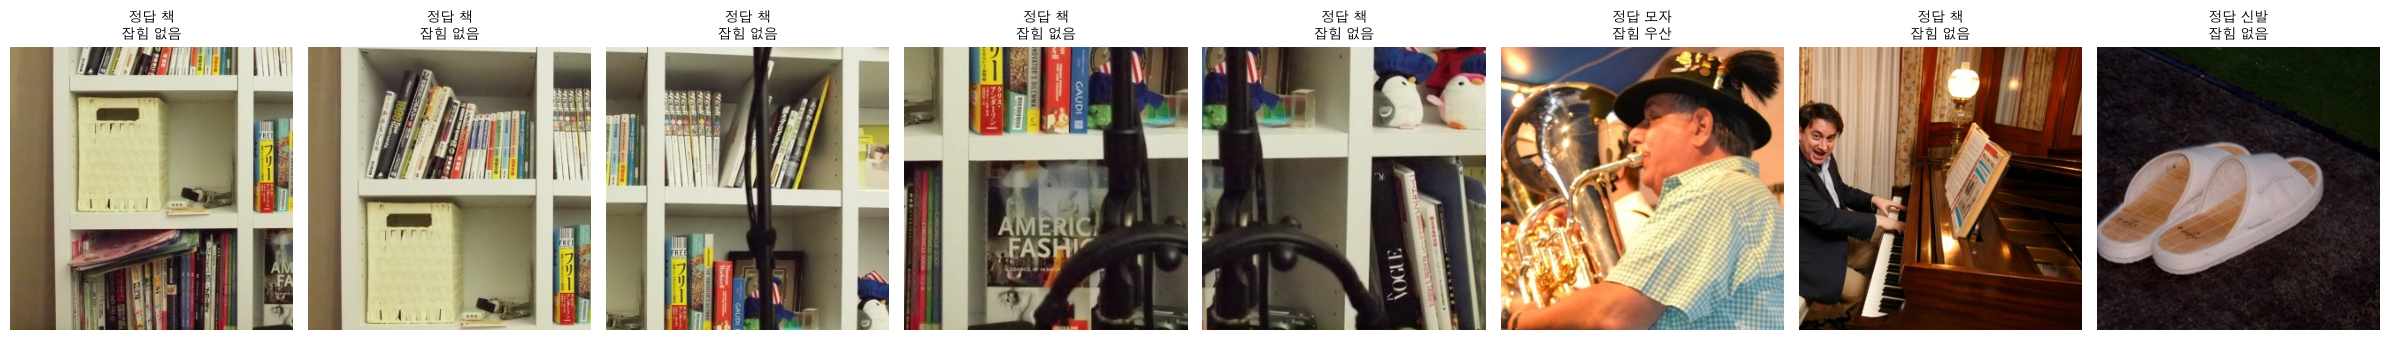

In [11]:
# 모델 C가 못 통과한 예시 몇 장
fails = pass_rows['C'][~pass_rows['C']['passed']].head(8)
if len(fails):
    fig, axes = plt.subplots(1, len(fails), figsize=(3 * len(fails), 3.4), squeeze=False)
    for ax, (_, r) in zip(axes[0], fails.iterrows()):
        ax.imshow(cv2.imread(str(CROPS_DIR / r['file']))[:, :, ::-1])
        ax.set_title(f"정답 {C.BY_KEY[r['cls_key']].ko}\n잡힘 {C.BY_KEY[r['pred_key']].ko if r['pred_key'] != '-' else '없음'}", fontsize=10)
        ax.axis('off')
    plt.tight_layout(); plt.show()

### 6-1. 튜닝 없이 COCO YOLO 그대로 쓰면?

미션 물건을 **COCO 80종 안에서만** 고른다면 학습 없이도 앱을 만들 수 있다. 우리 10종 중 COCO에 있는 4종(마우스 · 우산 · 책 · 칫솔)으로
**같은 crop, 같은 앱 규칙**에서 비교한다.

- COCO 그대로: 미션 4종만 찾도록 설정한 앱 (사람 · 컵 등 다른 COCO 클래스는 버림 → `class_map`)
- A · C (튜닝): 10종 중에서 고르므로 **선택지가 더 많아 오히려 불리**하다 (예: 책을 신발로 착각할 수 있음)

> §5의 mAP 비교(기준선 0.04 → A 0.33 등)는 Open Images 방식 그대로 시험 본 것이라 튜닝 모델에 유리했다.
> 여기서는 "물건 하나를 크게 비추는" 앱 장면으로 다시 본다.

In [12]:
base = YOLO('yolo11n.pt')                                  # COCO 80종으로 사전학습된 그대로
coco_map = {c.coco_id: c.id for c in C.OLD}                # COCO 번호 → 우리 번호 (64→0, 25→1, 73→2, 79→3)
old_keys = [c.key for c in C.OLD]
old_crops = crops[crops['cls_key'].isin(old_keys)].reset_index(drop=True)

base_rows = K.mission_pass_rate(base, old_crops, CROPS_DIR, conf=E.CONF, iou=E.IOU, min_side=E.MIN_SIDE,
                                imgsz=E.INPUT, device=DEVICE, class_map=coco_map)

no_tune = pd.DataFrame({'클래스': [C.BY_KEY[k].ko for k in old_keys]}, index=old_keys)
no_tune['COCO 그대로 (학습 0분)'] = base_rows.groupby('cls_key')['passed'].mean().reindex(old_keys)
for mn, df in pass_rows.items():
    mine = df[df['cls_key'].isin(old_keys)]
    no_tune[f'{mn} (튜닝)'] = mine.groupby('cls_key')['passed'].mean().reindex(old_keys)
no_tune['장수'] = old_crops.groupby('cls_key').size().reindex(old_keys)

total = {'클래스': '전체', 'COCO 그대로 (학습 0분)': base_rows['passed'].mean(), '장수': len(old_crops)}
for mn, df in pass_rows.items():
    total[f'{mn} (튜닝)'] = df[df['cls_key'].isin(old_keys)]['passed'].mean()
no_tune.loc['전체'] = pd.Series(total)
no_tune.round(2)

,클래스,COCO 그대로 (학습 0분),A (튜닝),C (튜닝),장수
mouse,마우스,0.64,1.00,1.00,22
umbrella,우산,0.76,0.80,0.80,25
book,책,0.04,0.56,0.25,123
toothbrush,칫솔,0.80,0.67,0.87,15
전체,전체,0.27,0.65,0.46,185


읽는 법
- COCO 그대로가 튜닝 모델과 **비슷하면** → 미션을 COCO 80종 안에서 고르는 한, 튜닝 없이도 충분하다 (학습 0분 · 데이터 0장)
- 튜닝 모델이 **확실히 높으면** → 같은 물건이라도 우리 데이터로 다시 배운 효과가 앱 장면에서도 있다
- 어느 쪽이든 모자 · 문 · 휴지 · 양말 · 신발 · 안경은 COCO에 **없어서** 튜닝 없이는 불가능하다 → "어떤 물건을 미션으로 쓸까"는 제품 결정

## 7. 결론 + 다음 단계

표를 보고 채운다 (숫자는 위 표에서 그대로 옮긴다).

- **가설 확인**: 책 · 신발 · 안경의 `학습효과(C청소-A청소)`가 다른 클래스보다 큰가? → ___
- **문**: 지울 박스가 15%뿐이라 거의 안 바뀔 것으로 예측했다. 실제로는? → ___
  (안 바뀌었다면 문의 낮은 점수는 장면 문제가 아니다 → 문 사진을 직접 보며 원인 찾기)
- **평가 문제였나**: `평가효과(A청소-A원본)`가 크면, A의 낮은 mAP 일부는 앱과 상관없는 장면 때문이었다. → ___
- **앱 기준**: 6절 통과율에서 C가 A보다 나은가? 전체 ___ → ___, 가장 많이 오른 클래스 ___
- **대가**: `C·원본`이 `A·원본`보다 얼마나 낮은가? (묶음 · 작은 박스를 덜 찾게 된 정도, 앱에는 상관없음) → ___

다음 단계 후보:

1. 통과율이 낮은 클래스의 실패 예시(6절 그림)를 보고 원인 분류 (다른 물건으로 잡힘 / 아무것도 못 잡음)
2. `MIN_AREA`(1%)를 바꿔 보기 (예: 2%, 5%) — 앱은 큰 물건만 보므로 더 세게 지워도 될지
3. 직접 찍은 사진(`my_photos/`)으로 A · C 통과율 비교 (`wakeup_mission.ipynb` 9절과 같은 방식)

### (선택) 더 나은 모델을 웹앱에 넣기

앱 기준 통과율(6절 `전체`)이 더 높은 모델을 ONNX(imgsz 320, opset 12)로 내보내 `docs/model.onnx`를 바꾼다.
**기본은 꺼져 있다** (`EXPORT_TO_APP = False`). 결과를 확인한 뒤 True로 바꾸고 이 셀만 실행한다.
클래스 10종은 그대로라 `docs/classes.js`는 바꿀 필요가 없다.

In [13]:
EXPORT_TO_APP = False
overall = {mn: df['passed'].mean() for mn, df in pass_rows.items()}
better = max(overall, key=overall.get)
print('앱 기준 통과율:', {k: round(v, 3) for k, v in overall.items()}, '→ 더 나은 모델:', better)
if EXPORT_TO_APP:
    onnx_path = Path(models[better].export(format='onnx', imgsz=320, opset=12, simplify=True, dynamic=False))
    shutil.copy(onnx_path, ROOT / 'docs' / 'model.onnx')
    print('docs/model.onnx 교체:', better, round((ROOT / 'docs' / 'model.onnx').stat().st_size / 1e6, 1), 'MB')
else:
    print('EXPORT_TO_APP = False → 웹앱 모델은 그대로')

앱 기준 통과율: {'A': np.float64(0.56), 'C': np.float64(0.502)} → 더 나은 모델: A
EXPORT_TO_APP = False → 웹앱 모델은 그대로
